# Extension: Comparison with Kaggle Vidwan Indian Faculty Dataset

**IDC409 Course Project — Topic 4: Web Scraping II (Faculty Profiles)**

This notebook provides a comparative analysis between our locally scraped IISER Mohali faculty dataset and the national **Vidwan: Indian Faculty and Researcher Dataset** (Kaggle: `mannacharya/vidwan-indian-faculty-and-researcher-dataset`, CC0 Public Domain).

### Objectives:
1. **Institution Categorization:** Classify profiles into **IISER Mohali**, **Other IISERs**, **IITs**, and **NITs**.
2. **Designation Mix:** Compare the seniority distribution across institute types.
3. **Research Keyword Extraction:** Use TF-IDF and term frequencies to contrast basic science research (IISERs) against engineering domains (IITs / NITs).
4. **Roster Match & Coverage:** Evaluate coverage and name alignment between our freshly scraped roster and the national self-reported portal.

### Step 1: Imports and Display Configuration

In [1]:
import re, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

### Step 2: Load the Vidwan Dataset

In [2]:
csv_files = glob.glob("vidwan_data/*.csv")
print("CSV files found:", csv_files)
vid = pd.read_csv(csv_files[0], low_memory=False)
print("Dataset Shape:", vid.shape)
vid.head()

CSV files found: ['vidwan_data\\indian_faculty_dataset.csv']
Dataset Shape: (15500, 15)
Out[0]: 
   Vidwan-ID                 Name             Position                                      Department          University Location                               Profile URL  \
0     556330  Ms Dixita Kagathara  Assistant Professor  Department of Computer Science and Engineering  Darshan University  Gujarat  https://darshan.irins.org/profile/556330   
1     556331   Mr Firoz Sherasiya  Assistant Professor  Department of Computer Science and Engineering  Darshan University  Gujarat  https://darshan.irins.org/profile/556331   
2     556358     Mr Bhavin Kanani  Assistant Professor            Department of Electrical Engineering  Darshan University  Gujarat  https://darshan.irins.org/profile/556358   
3     556374   Ms Vrunda Amrutiya  Assistant Professor            Department of Humanities and Science  Darshan University  Gujarat  https://darshan.irins.org/profile/556374   
4     556357      

,Vidwan-ID,Name,Position,Department,University,Location,Profile URL,Expertise,Experience,Qualification,Honours and Awards,Highest Qualification,Has Awards,Start Year,Years of Experience
0,556330,Ms Dixita Kagathara,Assistant Professor,Department of Computer Science and Engineering,Darshan University,Gujarat,https://darshan.irins.org/profile/556330,Computer Science Software Engineering,2021 - Present; Assistant Professor; Department of Computer Science and Engineering; Darshan University,2013; MTech; Gujarat University,NaN,MTech,0,2021.0,3.0
1,556331,Mr Firoz Sherasiya,Assistant Professor,Department of Computer Science and Engineering,Darshan University,Gujarat,https://darshan.irins.org/profile/556331,Computer Science Software Engineering,2022 - Present; Assistant Professor; Department of Computer Science and Engineering; Darshan University,2015; MTech; Gujarat Technological University,NaN,MTech,0,2022.0,2.0
2,556358,Mr Bhavin Kanani,Assistant Professor,Department of Electrical Engineering,Darshan University,Gujarat,https://darshan.irins.org/profile/556358,Electrical and Electronic Engineering,2021 - Present; Assistant Professor; Department of Electrical Engineering; Darshan University,2008; PhD; Gujarat Technological University,NaN,PhD,0,2021.0,3.0
3,556374,Ms Vrunda Amrutiya,Assistant Professor,Department of Humanities and Science,Darshan University,Gujarat,https://darshan.irins.org/profile/556374,"Humanities, Multidisciplinary",2024 - Present; Assistant Professor; Department of Humanities and Science; Darshan University,2023; MSc; Saurashtra University,NaN,MSc,0,2024.0,0.0
4,556357,Mr Raj Mehta,Assistant Professor,Department of Electrical Engineering,Darshan University,Gujarat,https://darshan.irins.org/profile/556357,Electrical and Electronic Engineering,2021 - Present; Assistant Professor; Department of Electrical Engineering; Darshan University,"2017; MTech; V.I.T. University, Vellore Tamilnadu",NaN,MTech,0,2021.0,3.0


### Step 3: Dataset Summary and Missing Values

In [3]:
print("Data Types:")
print(vid.dtypes)
print("\nMissing values (%):")
print((vid.isna().mean() * 100).round(1).sort_values(ascending=False))
for col in ["Position", "University", "Expertise"]:
    print(f"\n== {col} | unique values: {vid[col].nunique()} ==")
    print(vid[col].value_counts().head(5))

Data Types:
Vidwan-ID                  int64
Name                         str
Position                     str
Department                   str
University                   str
Location                     str
Profile URL                  str
Expertise                    str
Experience                   str
Qualification                str
Honours and Awards           str
Highest Qualification        str
Has Awards                 int64
Start Year               float64
Years of Experience      float64
dtype: object

Missing values (%):
Honours and Awards       54.3
Department                3.7
Qualification             3.1
Years of Experience       2.0
Start Year                2.0
Expertise                 1.7
Location                  1.2
Experience                0.7
Profile URL               0.0
Name                      0.0
Position                  0.0
Vidwan-ID                 0.0
University                0.0
Has Awards                0.0
Highest Qualification     0.0
dtype: f

### Step 4: Column Mapping Configuration

In [4]:
# Mapped from actual dataset schema
COL_NAME        = "Name"
COL_INSTITUTION = "University"
COL_DESIGNATION = "Position"
COL_TEXT_COLS   = ["Expertise", "Department"]

### Step 5: Classify Institutions into Groups

In [5]:
def classify_institute(x):
    if pd.isna(x):
        return "Unknown"
    s = str(x)
    if re.search(r"(IISER|Science Education (and|&) Research).{0,12}Mohali", s, re.I):
        return "IISER Mohali"
    if re.search(r"\bIISER\b|Science Education (and|&) Research", s, re.I):
        return "Other IISER"
    if re.search(r"\bIIT\b|Indian Institute of Technology", s, re.I):
        return "IIT"
    if re.search(r"\bNIT\b|National Institute of Technology", s, re.I):
        return "NIT"
    return "Other"

vid["Group"] = vid[COL_INSTITUTION].apply(classify_institute)
print("Group distribution:")
print(vid["Group"].value_counts())
for g in ["IISER Mohali", "Other IISER", "IIT", "NIT"]:
    print("\n---", g, "---")
    print(vid.loc[vid["Group"] == g, COL_INSTITUTION].value_counts().head(5))

Group distribution:
Group
Other           11359
IIT              2672
NIT              1278
Other IISER       155
IISER Mohali       36
Name: count, dtype: int64

--- IISER Mohali ---
University
Indian Institute of Science Education and Research, Mohali    36
Name: count, dtype: int64

--- Other IISER ---
University
Indian Institute of Science Education and Research, Pune                  48
Indian Institute of Science Education and Research, Kolkata               23
Indian Institute of Science Education and Research, Thiruvananthapuram    22
DAE-National Institute of Science Education and Research                  17
Indian Institute of Science Education and Research, Bhopal                15
Name: count, dtype: int64

--- IIT ---
University
Indian Institute of Technology Delhi        351
Indian Institute of Technology Madras       304
Indian Institute of Technology Bombay       301
Indian Institute of Technology Kharagpur    279
Indian Institute of Technology Kanpur       206
Name: c

### Step 6: Designation Mix by Institute Group

Out[0]: 
Position      Assistant Professor  Assistant Professor (Grade-I)  Associate Professor  Chair Professor  Other  Professor  Professor (HAG)
Group                                                                                                                                    
IISER Mohali                 16.7                            0.0                 27.8              0.0   11.1       41.7              2.8
IIT                           9.5                            2.1                 25.0              1.5    4.3       51.3              6.2
NIT                          23.2                            3.4                 28.8              0.0    2.6       37.9              4.1
Other IISER                  10.3                            0.6                 35.5              0.0    7.1       46.5              0.0


<ipython-input-1-233bbb954205>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


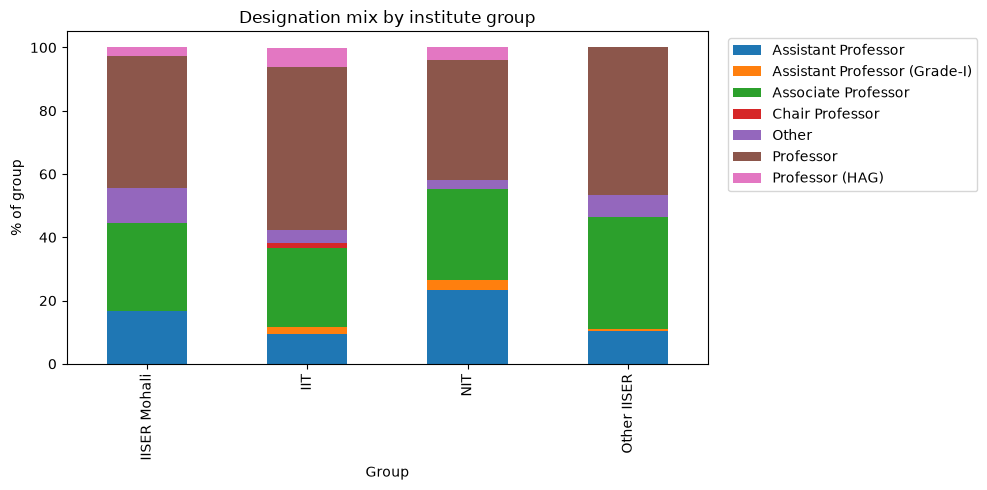

Position,Assistant Professor,Assistant Professor (Grade-I),Associate Professor,Chair Professor,Other,Professor,Professor (HAG)
Group,,,,,,,
IISER Mohali,16.7,0.0,27.8,0.0,11.1,41.7,2.8
IIT,9.5,2.1,25.0,1.5,4.3,51.3,6.2
NIT,23.2,3.4,28.8,0.0,2.6,37.9,4.1
Other IISER,10.3,0.6,35.5,0.0,7.1,46.5,0.0


In [6]:
GROUPS = ["IISER Mohali", "Other IISER", "IIT", "NIT"]
focus = vid[vid["Group"].isin(GROUPS)].copy()

top_des = focus[COL_DESIGNATION].value_counts().head(6).index
des_clean = focus[COL_DESIGNATION].where(focus[COL_DESIGNATION].isin(top_des), "Other")
tab = pd.crosstab(focus["Group"], des_clean, normalize="index").mul(100).round(1)
tab.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.ylabel("% of group")
plt.title("Designation mix by institute group")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
tab

### Step 7: TF-IDF Distinctive Keywords by Institute Group

In [7]:
GENERIC = {"research","study","studies","work","based","using","used","analysis","application",
           "applications","new","group","field","fields","area","areas","interest","interests"}
STOP = set(ENGLISH_STOP_WORDS) | GENERIC

def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"https?://\S+|\S+@\S+", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return " ".join(w for w in t.split() if w not in STOP and len(w) > 2)

focus["text"] = focus[COL_TEXT_COLS].fillna("").astype(str).apply(" ".join, axis=1).apply(clean_text)
focus = focus[focus["text"].str.len() > 0].reset_index(drop=True)
print("Profiles with text by Group:")
print(focus["Group"].value_counts())

group_docs = focus.groupby("Group")["text"].apply(" ".join)
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X = vec.fit_transform(group_docs)
terms = np.array(vec.get_feature_names_out())
print("\nTop distinctive terms per group:")
for i, g in enumerate(group_docs.index):
    row = X[i].toarray().ravel()
    print(f"{g:15} -> {', '.join(terms[row.argsort()[::-1][:12]])}")

Profiles with text by Group:
Group
IIT             2670
NIT             1277
Other IISER      155
IISER Mohali      36
Name: count, dtype: int64

Top distinctive terms per group:
IISER Mohali    -> department physical, sciences, department, chemical sciences, earth environmental, physical sciences, department biological, biological, biological sciences, chemical, department chemical, physical
IIT             -> mechanical, engineering, mechanical engineering, civil, civil engineering, aerospace engineering, aerospace, department mechanical, materials, engineering electrical, engineering department, electrical
NIT             -> engineering, mechanical engineering, mechanical, engineering electrical, electronics, communication, communication engineering, electronics communication, civil, civil engineering, department electronics, engineering department
Other IISER     -> biology biology, school physics, school, school chemistry, chemistry, physics school, chemistry chemistry, chemistry 

### Step 8: Keyword Share Across Institute Groups

In [8]:
cv = CountVectorizer(binary=True, min_df=10)
B = cv.fit_transform(focus["text"])
words = np.array(cv.get_feature_names_out())
share = pd.DataFrame(
    {g: np.asarray(B[(focus["Group"] == g).values].mean(axis=0)).ravel() * 100 for g in GROUPS},
    index=words)
share["overall"] = np.asarray(B.mean(axis=0)).ravel() * 100
top = share.sort_values("overall", ascending=False).head(20).drop(columns="overall").round(1)
top

Out[0]: 
                   IISER Mohali  Other IISER   IIT   NIT
department                 88.9         14.2  79.9  87.5
engineering                 0.0          3.9  65.5  73.5
electrical                  0.0          1.9  16.8  24.5
electronic                  0.0          1.9  14.6  22.9
science                     2.8          5.2  15.1  18.3
mechanical                  0.0          0.0  12.2  13.5
physics                    13.9         31.6  11.2   8.2
chemistry                  25.0         37.4   9.9   6.7
computer                    0.0          4.5   7.8  13.9
applied                     2.8          3.9   9.3   6.1
civil                       0.0          0.0   8.4   7.9
multidisciplinary           8.3         26.5   7.6   3.4
electronics                 0.0          0.0   3.4  15.6
chemical                   30.6         10.3   6.4   4.9
materials                   0.0          0.0   7.1   5.0
sciences                   88.9         28.4   5.1   1.6
school                

,IISER Mohali,Other IISER,IIT,NIT
department,88.9,14.2,79.9,87.5
engineering,0.0,3.9,65.5,73.5
electrical,0.0,1.9,16.8,24.5
electronic,0.0,1.9,14.6,22.9
science,2.8,5.2,15.1,18.3
mechanical,0.0,0.0,12.2,13.5
physics,13.9,31.6,11.2,8.2
chemistry,25.0,37.4,9.9,6.7
computer,0.0,4.5,7.8,13.9
applied,2.8,3.9,9.3,6.1


### Step 9: Match Scraped Faculty List with Vidwan Profiles

In [9]:
ours = pd.read_csv("faculty_eda_done.csv")

def norm_name(n):
    n = str(n).lower()
    n = re.sub(r"\b(prof|professor|dr|mr|ms|mrs)\b\.?", " ", n)
    n = re.sub(r"[^a-z\s]", " ", n)
    return " ".join(sorted(n.split()))

vid_mohali = vid[vid["Group"] == "IISER Mohali"]
matched = set(ours["Name"].apply(norm_name)) & set(vid_mohali[COL_NAME].apply(norm_name))
print(f"{len(ours)} faculty on our scraped list | {len(vid_mohali)} IISER Mohali profiles in Vidwan | {len(matched)} name matches")
print("Match rate of Vidwan profiles against our list:", f"{len(matched) / len(vid_mohali) * 100:.1f}%")

135 faculty on our scraped list | 36 IISER Mohali profiles in Vidwan | 29 name matches
Match rate of Vidwan profiles against our list: 80.6%


### Step 10: Save Summary Output Tables

In [10]:
focus.groupby("Group").size().to_csv("vidwan_group_sizes.csv")
top.to_csv("vidwan_keyword_share_by_group.csv")
print("Saved vidwan_group_sizes.csv and vidwan_keyword_share_by_group.csv successfully!")

Saved vidwan_group_sizes.csv and vidwan_keyword_share_by_group.csv successfully!
